# Approximate Nearest Neighbor (ANN) Benchmark Experiments
## Comparing ANNOY, FAISS, and HNSW across Distance Metrics, Dataset Sizes, and Dimensions

### Experimental Setup
- **Algorithms:**
  1. **ANNOY** (*Approximate Nearest Neighbors Oh Yeah*)
  2. **FAISS** (*Facebook AI Similarity Search* — `IndexIVFFlat`)
  3. **HNSW** (*Hierarchical Navigable Small World* — `hnswlib`)
- **Dataset Sizes ($N$):** `1,000` vs. `1,000,000` data points
- **Dimensions ($D$):** `2D` vs. `5D` (`1,000/2D`, `1,000/5D`, `1,000,000/2D`, `1,000,000/5D`)
- **Distance Metrics:**
  - **Euclidean (L2)** (`euclidean` in Annoy, `METRIC_L2` in FAISS, `l2` in HNSW)
  - **Cosine / Angular** (`angular` in Annoy, L2-normalized `METRIC_INNER_PRODUCT` in FAISS, `cosine` in HNSW)
- **Recorded Metrics:** Index Build Time (`s`), Average Query Time (`ms/query`), and `Recall@10 (%)`

In [1]:
!pip install -q annoy faiss-cpu hnswlib numpy pandas matplotlib


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [2]:
import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from annoy import AnnoyIndex
import faiss
import hnswlib

# Reproducibility seed
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Experiment parameters
DATASET_SIZES = [1_000, 1_000_000]
DIMENSIONS = [2, 5]
DISTANCE_METRICS = ["Euclidean", "Cosine"]

NUM_QUERIES = 100   # Number of query vectors per experiment
TOP_K = 10          # Number of nearest neighbors to retrieve (k=10)

# Algorithm hyperparameters
ANNOY_TREES = 10
HNSW_M = 16
HNSW_EF_CONSTRUCTION = 100
HNSW_EF_SEARCH = 50
FAISS_NPROBE = 10

In [3]:
def generate_synthetic_data(n_samples: int, dim: int, n_queries: int, seed: int = 42):
    """Generates random float32 database vectors and query vectors."""
    rng = np.random.default_rng(seed)
    data = rng.random((n_samples, dim), dtype=np.float32)
    queries = rng.random((n_queries, dim), dtype=np.float32)
    return np.ascontiguousarray(data), np.ascontiguousarray(queries)


def compute_ground_truth(data: np.ndarray, queries: np.ndarray, metric: str, k: int):
    """Computes exact k-NN indices using FAISS flat brute-force search for Recall@k."""
    dim = data.shape[1]
    if metric == "Euclidean":
        gt_index = faiss.IndexFlatL2(dim)
        gt_index.add(data)
        _, gt_indices = gt_index.search(queries, k)
    elif metric == "Cosine":
        data_norm = data.copy()
        queries_norm = queries.copy()
        faiss.normalize_L2(data_norm)
        faiss.normalize_L2(queries_norm)
        gt_index = faiss.IndexFlatIP(dim)
        gt_index.add(data_norm)
        _, gt_indices = gt_index.search(queries_norm, k)
    else:
        raise ValueError(f"Unsupported metric: {metric}")
    return gt_indices


def calculate_recall(pred_indices: np.ndarray, gt_indices: np.ndarray) -> float:
    """Calculates mean Recall@k (%) between predicted and exact ground-truth indices."""
    k = gt_indices.shape[1]
    recalls = [
        len(set(pred).intersection(set(gt))) / k
        for pred, gt in zip(pred_indices, gt_indices)
    ]
    return float(np.mean(recalls) * 100.0)

In [4]:
def benchmark_annoy(data: np.ndarray, queries: np.ndarray, metric: str, k: int, gt_indices: np.ndarray):
    """Builds and queries an ANNOY index, returning build time, avg query time, and Recall@k."""
    n_samples, dim = data.shape
    annoy_metric = "euclidean" if metric == "Euclidean" else "angular"

    # 1. Build Index
    t0 = time.perf_counter()
    index = AnnoyIndex(dim, annoy_metric)
    for i in range(n_samples):
        index.add_item(i, data[i])
    index.build(ANNOY_TREES)
    build_time = time.perf_counter() - t0

    # 2. Query Index
    pred_indices = np.empty((len(queries), k), dtype=np.int64)
    t0 = time.perf_counter()
    for i, q in enumerate(queries):
        pred_indices[i] = index.get_nns_by_vector(q, k, search_k=-1)
    total_query_time = time.perf_counter() - t0
    avg_query_ms = (total_query_time / len(queries)) * 1000.0

    # 3. Compute Recall@k
    recall = calculate_recall(pred_indices, gt_indices)
    return build_time, avg_query_ms, recall


def benchmark_faiss(data: np.ndarray, queries: np.ndarray, metric: str, k: int, gt_indices: np.ndarray):
    """Builds and queries a FAISS IndexIVFFlat index, returning build time, avg query time, and Recall@k."""
    n_samples, dim = data.shape
    nlist = 32 if n_samples <= 10_000 else 256

    if metric == "Euclidean":
        db_vectors = data
        q_vectors = queries
        quantizer = faiss.IndexFlatL2(dim)
        faiss_metric = faiss.METRIC_L2
    else:
        db_vectors = data.copy()
        q_vectors = queries.copy()
        faiss.normalize_L2(db_vectors)
        faiss.normalize_L2(q_vectors)
        quantizer = faiss.IndexFlatIP(dim)
        faiss_metric = faiss.METRIC_INNER_PRODUCT

    # 1. Build Index
    t0 = time.perf_counter()
    index = faiss.IndexIVFFlat(quantizer, dim, nlist, faiss_metric)
    index.train(db_vectors)
    index.add(db_vectors)
    build_time = time.perf_counter() - t0

    # 2. Query Index
    index.nprobe = min(FAISS_NPROBE, nlist)
    t0 = time.perf_counter()
    _, pred_indices = index.search(q_vectors, k)
    total_query_time = time.perf_counter() - t0
    avg_query_ms = (total_query_time / len(queries)) * 1000.0

    # 3. Compute Recall@k
    recall = calculate_recall(pred_indices, gt_indices)
    return build_time, avg_query_ms, recall


def benchmark_hnsw(data: np.ndarray, queries: np.ndarray, metric: str, k: int, gt_indices: np.ndarray):
    """Builds and queries an HNSW (hnswlib) index, returning build time, avg query time, and Recall@k."""
    n_samples, dim = data.shape
    space = "l2" if metric == "Euclidean" else "cosine"

    # 1. Build Index
    t0 = time.perf_counter()
    index = hnswlib.Index(space=space, dim=dim)
    index.init_index(max_elements=n_samples, ef_construction=HNSW_EF_CONSTRUCTION, M=HNSW_M)
    index.add_items(data, np.arange(n_samples))
    build_time = time.perf_counter() - t0

    # 2. Query Index
    index.set_ef(HNSW_EF_SEARCH)
    t0 = time.perf_counter()
    pred_indices, _ = index.knn_query(queries, k=k)
    total_query_time = time.perf_counter() - t0
    avg_query_ms = (total_query_time / len(queries)) * 1000.0

    # 3. Compute Recall@k
    recall = calculate_recall(pred_indices, gt_indices)
    return build_time, avg_query_ms, recall

In [5]:
results = []

for metric in DISTANCE_METRICS:
    print(f"{'='*65}")
    print(f"Running Experiments for Distance Metric: {metric}")
    print(f"{'='*65}")

    for n_samples in DATASET_SIZES:
        for dim in DIMENSIONS:
            config_label = f"{n_samples:,}/{dim}D"
            print(f"\n[Dataset: {config_label} | Metric: {metric}] Generating data & ground truth...")
            data, queries = generate_synthetic_data(n_samples, dim, NUM_QUERIES, seed=RANDOM_SEED)
            gt_indices = compute_ground_truth(data, queries, metric, TOP_K)

            for algo_name, bench_fn in [
                ("ANNOY", benchmark_annoy),
                ("FAISS", benchmark_faiss),
                ("HNSW", benchmark_hnsw),
            ]:
                build_s, query_ms, recall_pct = bench_fn(data, queries, metric, TOP_K, gt_indices)
                print(f"  -> {algo_name:<6} | Build: {build_s:6.3f}s | Query: {query_ms:7.4f} ms/q | Recall@{TOP_K}: {recall_pct:6.2f}%")

                results.append({
                    "Distance Metric": metric,
                    "Number of Data/Dimensions": config_label,
                    "Data Points": n_samples,
                    "Dimensions": f"{dim}D",
                    "Algorithm": algo_name,
                    "Build Time (s)": round(build_s, 4),
                    "Query Time (ms)": round(query_ms, 4),
                    f"Recall@{TOP_K} (%)": round(recall_pct, 2),
                    "Summary": f"Build: {build_s:.2f}s | Query: {query_ms:.3f}ms | Recall: {recall_pct:.1f}%"
                })

            del data, queries, gt_indices
            gc.collect()

df_results = pd.DataFrame(results)
print("\nAll experiments completed successfully!")

Running Experiments for Distance Metric: Euclidean

[Dataset: 1,000/2D | Metric: Euclidean] Generating data & ground truth...
  -> ANNOY  | Build:  0.006s | Query:  0.0224 ms/q | Recall@10:  99.80%
  -> FAISS  | Build:  0.002s | Query:  0.0030 ms/q | Recall@10: 100.00%
  -> HNSW   | Build:  0.006s | Query:  0.0212 ms/q | Recall@10: 100.00%

[Dataset: 1,000/5D | Metric: Euclidean] Generating data & ground truth...
  -> ANNOY  | Build:  0.005s | Query:  0.0200 ms/q | Recall@10:  96.90%
  -> FAISS  | Build:  0.001s | Query:  0.0025 ms/q | Recall@10:  99.90%
  -> HNSW   | Build:  0.005s | Query:  0.0205 ms/q | Recall@10: 100.00%

[Dataset: 1,000,000/2D | Metric: Euclidean] Generating data & ground truth...
  -> ANNOY  | Build:  3.171s | Query:  0.0417 ms/q | Recall@10:  99.70%
  -> FAISS  | Build:  0.580s | Query:  0.0226 ms/q | Recall@10: 100.00%
  -> HNSW   | Build:  4.134s | Query:  0.0249 ms/q | Recall@10: 100.00%

[Dataset: 1,000,000/5D | Metric: Euclidean] Generating data & ground tr

In [6]:
row_order = ["1,000/2D", "1,000/5D", "1,000,000/2D", "1,000,000/5D"]
col_order = ["ANNOY", "FAISS", "HNSW"]

for metric in DISTANCE_METRICS:
    print(f"\n{'#'*80}")
    print(f"DISTANCE METRIC: {metric.upper()} — COMBINED PERFORMANCE SUMMARY")
    print(f"{'#'*80}")
    subset = df_results[df_results["Distance Metric"] == metric]

    pivot_summary = subset.pivot(
        index="Number of Data/Dimensions",
        columns="Algorithm",
        values="Summary"
    ).reindex(index=row_order, columns=col_order)
    display(pivot_summary)

    print(f"\n--- {metric}: Average Query Time (ms/query) ---")
    display(subset.pivot(index="Number of Data/Dimensions", columns="Algorithm", values="Query Time (ms)").reindex(index=row_order, columns=col_order))

    print(f"\n--- {metric}: Index Build Time (seconds) ---")
    display(subset.pivot(index="Number of Data/Dimensions", columns="Algorithm", values="Build Time (s)").reindex(index=row_order, columns=col_order))

    print(f"\n--- {metric}: Recall@{TOP_K} (%) ---")
    display(subset.pivot(index="Number of Data/Dimensions", columns="Algorithm", values=f"Recall@{TOP_K} (%)").reindex(index=row_order, columns=col_order))


################################################################################
DISTANCE METRIC: EUCLIDEAN — COMBINED PERFORMANCE SUMMARY
################################################################################


Algorithm,ANNOY,FAISS,HNSW
Number of Data/Dimensions,,,
"1,000/2D",Build: 0.01s | Query: 0.022ms | Recall: 99.8%,Build: 0.00s | Query: 0.003ms | Recall: 100.0%,Build: 0.01s | Query: 0.021ms | Recall: 100.0%
"1,000/5D",Build: 0.01s | Query: 0.020ms | Recall: 96.9%,Build: 0.00s | Query: 0.002ms | Recall: 99.9%,Build: 0.00s | Query: 0.021ms | Recall: 100.0%
"1,000,000/2D",Build: 3.17s | Query: 0.042ms | Recall: 99.7%,Build: 0.58s | Query: 0.023ms | Recall: 100.0%,Build: 4.13s | Query: 0.025ms | Recall: 100.0%
"1,000,000/5D",Build: 2.85s | Query: 0.040ms | Recall: 96.3%,Build: 0.68s | Query: 0.026ms | Recall: 100.0%,Build: 7.12s | Query: 0.036ms | Recall: 100.0%



--- Euclidean: Average Query Time (ms/query) ---


Algorithm,ANNOY,FAISS,HNSW
Number of Data/Dimensions,,,
"1,000/2D",0.0224,0.0030,0.0212
"1,000/5D",0.0200,0.0025,0.0205
"1,000,000/2D",0.0417,0.0226,0.0249
"1,000,000/5D",0.0404,0.0257,0.0364



--- Euclidean: Index Build Time (seconds) ---


Algorithm,ANNOY,FAISS,HNSW
Number of Data/Dimensions,,,
"1,000/2D",0.0056,0.0024,0.0055
"1,000/5D",0.0051,0.0009,0.0048
"1,000,000/2D",3.1708,0.5796,4.1339
"1,000,000/5D",2.8547,0.6762,7.1225


... (6 outputs left out)


--- Cosine: Index Build Time (seconds) ---


Algorithm,ANNOY,FAISS,HNSW
Number of Data/Dimensions,,,
"1,000/2D",0.0075,0.0012,0.0049
"1,000/5D",0.0064,0.0011,0.0060
"1,000,000/2D",8.0848,0.2783,7.6498
"1,000,000/5D",3.2601,0.4168,5.6882



--- Cosine: Recall@10 (%) ---


Algorithm,ANNOY,FAISS,HNSW
Number of Data/Dimensions,,,
"1,000/2D",99.8,100.0,100.0
"1,000/5D",97.4,100.0,100.0
"1,000,000/2D",4.1,98.4,35.5
"1,000,000/5D",96.6,100.0,100.0


,Distance Metric,Number of Data/Dimensions,Algorithm,Build Time (s),Query Time (ms),Recall@10 (%)
0,Euclidean,"1,000/2D",ANNOY,0.0056,0.0224,99.8
1,Euclidean,"1,000/2D",FAISS,0.0024,0.0030,100.0
2,Euclidean,"1,000/2D",HNSW,0.0055,0.0212,100.0
3,Euclidean,"1,000/5D",ANNOY,0.0051,0.0200,96.9
4,Euclidean,"1,000/5D",FAISS,0.0009,0.0025,99.9
5,Euclidean,"1,000/5D",HNSW,0.0048,0.0205,100.0
6,Euclidean,"1,000,000/2D",ANNOY,3.1708,0.0417,99.7
7,Euclidean,"1,000,000/2D",FAISS,0.5796,0.0226,100.0
8,Euclidean,"1,000,000/2D",HNSW,4.1339,0.0249,100.0
9,Euclidean,"1,000,000/5D",ANNOY,2.8547,0.0404,96.3


Saved results to 'ann_benchmark_results.csv'


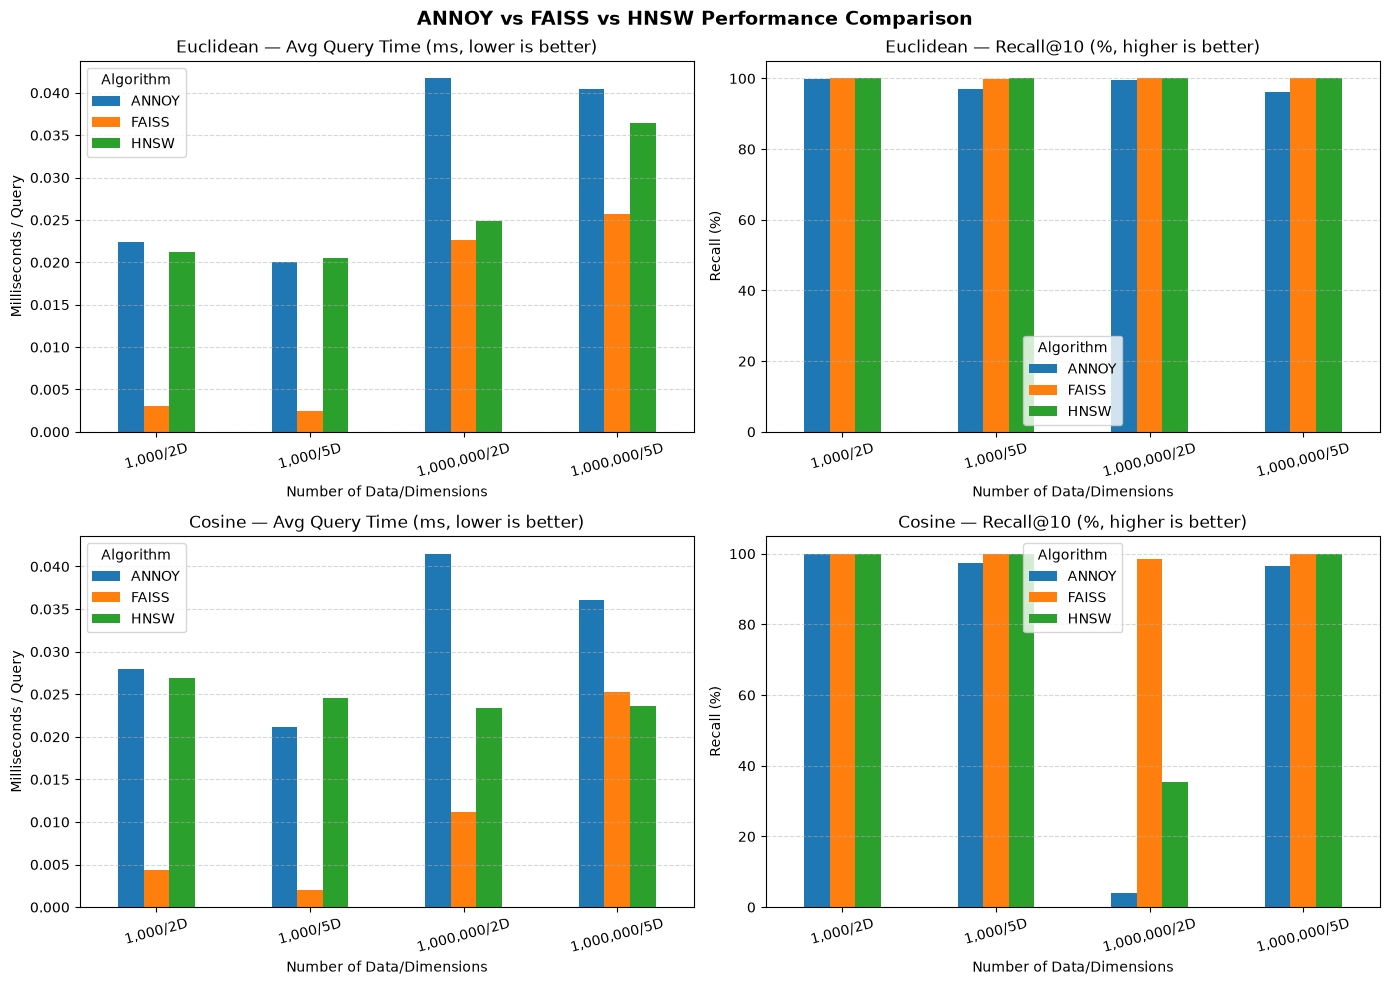

In [7]:
# Display full unpivoted table
display(df_results.drop(columns=["Data Points", "Dimensions", "Summary"]))

# Save results to CSV
df_results.to_csv("ann_benchmark_results.csv", index=False)
print("Saved results to 'ann_benchmark_results.csv'")

# Plot Query Time and Recall@10 comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("ANNOY vs FAISS vs HNSW Performance Comparison", fontsize=14, fontweight="bold")

for idx, metric in enumerate(DISTANCE_METRICS):
    subset = df_results[df_results["Distance Metric"] == metric]

    # Query Time subplot
    ax_q = axes[idx, 0]
    q_pivot = subset.pivot(index="Number of Data/Dimensions", columns="Algorithm", values="Query Time (ms)").reindex(index=row_order, columns=col_order)
    q_pivot.plot(kind="bar", ax=ax_q, rot=15)
    ax_q.set_title(f"{metric} — Avg Query Time (ms, lower is better)")
    ax_q.set_ylabel("Milliseconds / Query")
    ax_q.grid(axis="y", linestyle="--", alpha=0.5)

    # Recall subplot
    ax_r = axes[idx, 1]
    r_pivot = subset.pivot(index="Number of Data/Dimensions", columns="Algorithm", values=f"Recall@{TOP_K} (%)").reindex(index=row_order, columns=col_order)
    r_pivot.plot(kind="bar", ax=ax_r, rot=15)
    ax_r.set_title(f"{metric} — Recall@{TOP_K} (%, higher is better)")
    ax_r.set_ylabel("Recall (%)")
    ax_r.set_ylim(0, 105)
    ax_r.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()